# Étape 5 — Classification supervisée
**Goal:** learn to predict the K-Means cluster from patient medical features, with a leakage-free workflow.



## 0. Setup and imports
Import pandas, numpy, matplotlib/seaborn, sklearn (model_selection, pipeline, preprocessing, impute, linear_model, ensemble, svm, dummy, metrics, inspection), imblearn, joblib. Set a global `RANDOM_STATE = 42`.

In [ ]:
%load_ext autoreload
%autoreload 2

import sys 
from pathlib import Path

projectRoot = Path.cwd().parent.parent
sys.path.append(str(projectRoot))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import src.data.extracting as Loader
import src.data.charts as Painter

from sklearn.model_selection import train_test_split
import src.data.processing as Processor



import mlflow, mlflow.sklearn


import src.utils.mlflowconf


RANDOM_STATE = 42



## 1. Load the clustered data and sanity-check
- Load `clustered_df` (from Step 4 or from a saved CSV).
- Check shape, dtypes, missing values, and `Cluster` values.
- Check that the Pima-style columns with impossible zeros (Glucose, BloodPressure, SkinThickness, Insulin, BMI) are handled consistently with your cleaning step. **Do not impute here**; imputation goes in the pipeline.

In [2]:
cluster_df = Loader.readData('cluster')

cluster_df.info()

display(cluster_df['cluster'].unique())
display(cluster_df['risk_score'].unique())

grouped = cluster_df.groupby('cluster').count()
display(grouped)

grouped = cluster_df.groupby('risk_score').count()
display(grouped)


/home/mdebbarh/Desktop/projects/python/Suga/data/processed/cluster_data.csv
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Glucose                   768 non-null    int64  
 1   BloodPressure             768 non-null    int64  
 2   SkinThickness             768 non-null    float64
 3   Insulin                   768 non-null    int64  
 4   BMI                       768 non-null    float64
 5   DiabetesPedigreeFunction  768 non-null    float64
 6   Age                       768 non-null    int64  
 7   cluster                   768 non-null    int64  
 8   risk_score                768 non-null    str    
dtypes: float64(3), int64(5), str(1)
memory usage: 56.7 KB


array([1, 0])

<ArrowStringArray>
['High', 'Low']
Length: 2, dtype: str

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,risk_score
cluster,,,,,,,,
0,408,408,408,408,408,408,408,408
1,360,360,360,360,360,360,360,360


,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,cluster
risk_score,,,,,,,,
High,360,360,360,360,360,360,360,360
Low,408,408,408,408,408,408,408,408


## 2. Define `y` and `X`
- `y = clustered_df['Cluster']` (class labels, not continuous values).
- `X` = the **same features used for clustering**.
- **Exclude** `Cluster` (the answer) and `Outcome` (a different target).
- Print the feature list so it is documented.

In [3]:
features = cluster_df.drop(columns=['cluster', 'risk_score'])
target = cluster_df['cluster']

print(features.columns)

Index(['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI',
       'DiabetesPedigreeFunction', 'Age'],
      dtype='str')


## 3. Train/test split (then lock the test set)
`train_test_split(..., test_size=0.2, stratify=y, random_state=RANDOM_STATE)`.
Check that class proportions are similar in train and test. From now on, **do not touch `X_test`/`y_test`** until Section 9.

In [4]:
train_features , test_features, train_target, test_target = train_test_split(features, target, test_size = 0.3, stratify = target, random_state = RANDOM_STATE )

In [5]:
display(train_features.shape)
display(train_target.shape)
display(test_features.shape)
display(test_target.shape)

(537, 7)

(537,)

(231, 7)

(231,)

## 4. Class balance check
- `value_counts()` and `value_counts(normalize=True)` on `y_train`.
- Bar plot of the distribution.
- **Decision rule (write your conclusion in a markdown cell):** if the smallest class is below ~20% of the data, test resampling; otherwise state that classes are balanced and no resampling is needed. Alternative: `class_weight='balanced'` on the models.

In [6]:


con = pd.concat(
    [   train_target.value_counts().to_frame(name = 'train_target'),
        train_target.value_counts(normalize=True).to_frame(name='train_target_normalized'),
        test_target.value_counts().to_frame(name='test_target'),
        test_target.value_counts(normalize=True).to_frame(name = 'test_target_normalized')], axis=1)
display(con)

,train_target,train_target_normalized,test_target,test_target_normalized
cluster,,,,
0,285,0.530726,123,0.532468
1,252,0.469274,108,0.467532


## 5. Preprocessing and pipeline design
- Build a preprocessing block: `SimpleImputer(strategy='median')` then `StandardScaler()`.
- Build a **dictionary of full pipelines** (one per model): Logistic Regression, Random Forest, SVM (+ optionally KNN / Gradient Boosting).
- If resampling is justified, use `imblearn.pipeline.Pipeline` with `RandomOverSampler` or `RandomUnderSampler` as the first step, so it is applied to training folds only.
- Note: scaling is kept for Random Forest for a uniform pipeline (harmless), or omit it and justify.

In [ ]:
import src.models.baseline_training as BaseTrain

result = BaseTrain.train(train_features, train_target, test_features, test_target)

2026/10/07 16:49:51 INFO mlflow.tracking.fluent: Experiment with name 'baseline training' does not exist. Creating a new experiment.
2026/10/07 16:49:51 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/07 16:49:53 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/07 16:49:55 WARNING mlflow.sklearn: Saving scikit-learn m

fulltime: 12.380047946000559


,name,model,accuracy,f1 score,time
0,logistic,"(StandardScaler(), LogisticRegression())",0.995671,0.995392,0.013757
1,svm,"(StandardScaler(), SVC())",0.987013,0.986175,0.007922
2,knn,"(StandardScaler(), KNeighborsClassifier())",0.961039,0.958140,0.007003
3,random_forest,"(DecisionTreeClassifier(max_features='sqrt', r...",0.948052,0.944954,0.096703
4,gboost,"([DecisionTreeRegressor(max_depth=3,\n ...",0.935065,0.929577,0.092596
5,decision_tree,DecisionTreeClassifier(),0.878788,0.875000,0.004447


## 6. Baseline and model comparison (cross-validation on train only)
- `DummyClassifier(strategy='most_frequent')` as a baseline.
- `StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)`.
- For each model, run `cross_validate` with scoring: accuracy, balanced_accuracy, precision_weighted, recall_weighted, f1_weighted, f1_macro. Use `return_train_score=True`.
- Build a comparison DataFrame (mean ± std) and a boxplot/bar plot of the F1 scores.

In [8]:
from src.models.crossValidation import crossVlaidations



result = crossVlaidations(train_features, train_target)

display(result)



2026/10/07 16:50:03 INFO mlflow.tracking.fluent: Experiment with name 'Cross Validation' does not exist. Creating a new experiment.


Started run: 9b6b7fe3acc64455b938bba6fbea0255
Started run: ccbd83b619f141299c5e7ad41a599eea
Started run: d1f16d18d49a473aa26761d1da139b66
Started run: b305406919144afa866795ca33764d8c
Started run: 10be60747bf64d61b3c0721a31116e67
Started run: 3bb30798cd2e46cc81179a814cd77185
Started run: dc7dc07d198147e09bb12ba091fd7f41


,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_weighted_mean,f1_weighted_std,f1_macro_mean,f1_macro_std,train_f1_weighted_mean,train_f1_weighted_std,f1_gap
0,logistic,0.986951,0.018303,0.987307,0.017335,0.987926,0.016708,0.986951,0.018303,0.986954,0.018290,0.986927,0.018316,0.994413,0.001864,0.007460
1,svm,0.972049,0.019621,0.973065,0.018320,0.973863,0.016683,0.972049,0.019621,0.972050,0.019623,0.972000,0.019606,0.987896,0.001755,0.015846
2,knn,0.919851,0.017584,0.918322,0.017219,0.920612,0.018361,0.919851,0.017584,0.919727,0.017548,0.919321,0.017642,0.957100,0.004866,0.037373
3,random_forest,0.925528,0.010101,0.925796,0.010777,0.926486,0.010177,0.925528,0.010101,0.925523,0.010145,0.925276,0.010209,1.000000,0.000000,0.074477
4,gboost,0.921859,0.018837,0.921874,0.019065,0.923035,0.019229,0.921859,0.018837,0.921832,0.018839,0.921563,0.018882,1.000000,0.000000,0.078168
5,decision_tree,0.864088,0.027920,0.864413,0.028795,0.865338,0.029196,0.864088,0.027920,0.864108,0.027907,0.863686,0.028042,1.000000,0.000000,0.135892
6,Dummy,0.530737,0.002416,0.500000,0.000000,0.281688,0.002563,0.530737,0.002416,0.368038,0.002769,0.346718,0.001032,0.368023,0.000694,-0.000015


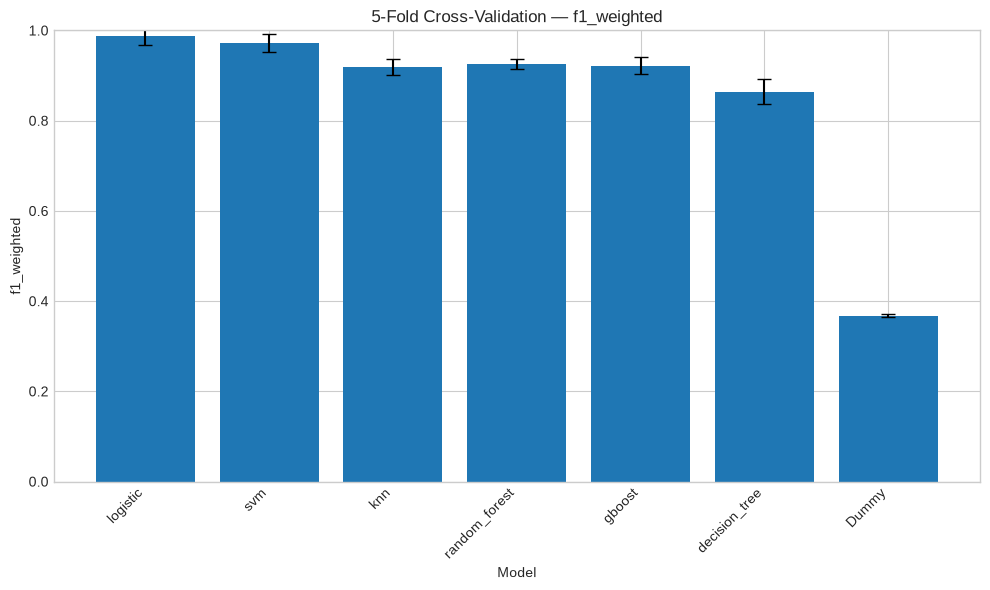

In [9]:
import src.data.charts as Painter

Painter.drawBarPlot(result, 'f1_weighted')

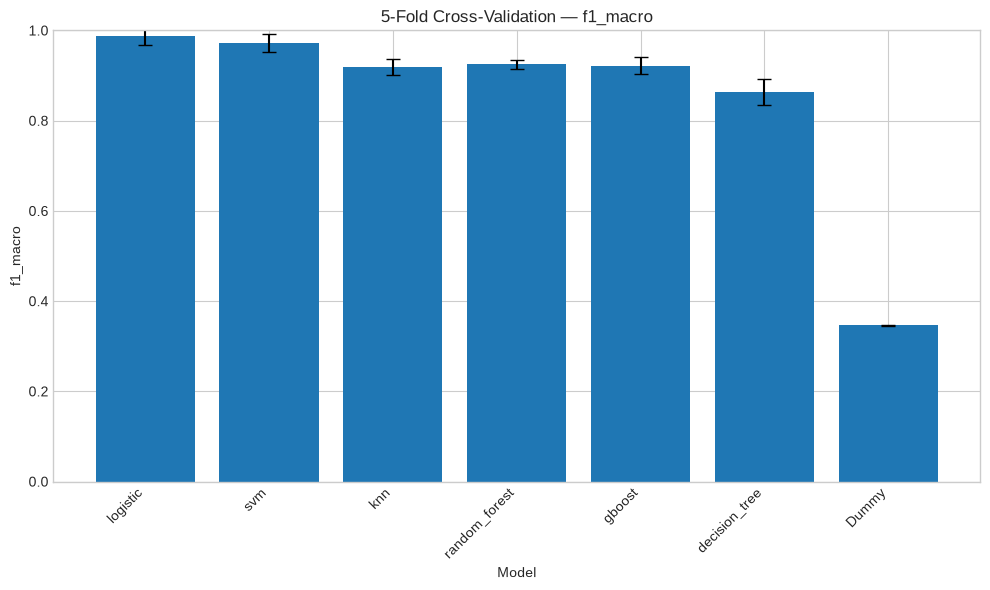

In [10]:
Painter.drawBarPlot(result, 'f1_macro')

## 7. (Conditional) Resampling experiment
Only if Section 4 showed imbalance:
- Compare **no resampling** vs `RandomOverSampler` vs `RandomUnderSampler`, using the imblearn pipeline and the same CV.
- Report weighted F1 **and** macro F1 (macro reveals minority-class problems).
- Otherwise, write a markdown cell: *"Les classes étant relativement équilibrées, aucun rééchantillonnage n'a été nécessaire."*

## 8. Hyperparameter tuning (GridSearchCV / RandomizedSearchCV, train only)
For **each** model:
- Define the `param_grid` using the pipeline step prefix (e.g. `classifier__C`, `classifier__n_estimators`).
- Suggested grids: LR (`C`, `penalty`/`solver`), RF (`n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`), SVM (`C`, `kernel`, `gamma`).
- `scoring='f1_weighted'`, `cv=StratifiedKFold(5)`, `n_jobs=-1`, `refit=True`.
- Use `RandomizedSearchCV` if the Random Forest grid is too slow.
- Store `best_params_`, `best_score_`, `best_estimator_` for each model in a summary table.

In [11]:
import src.models.hypertuning as Optimizer

summary = Optimizer.hypertune(train_features, train_target)


2026/10/07 16:50:06 INFO mlflow.tracking.fluent: Experiment with name 'hyperturning models' does not exist. Creating a new experiment.



Tuning Logistic...
Best parameters:
{'classifier__C': 100, 'classifier__solver': 'liblinear'}
Best CV F1: 0.9925

Tuning knn...
Best parameters:
{'classifier__metric': 'euclidean', 'classifier__n_neighbors': 11, 'classifier__p': 1, 'classifier__weights': 'distance'}
Best CV F1: 0.9440

Tuning svm...
Best parameters:
{'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}
Best CV F1: 0.9944

Tuning random_forest...
Best parameters:
{'classifier__n_estimators': 300, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': None}
Best CV F1: 0.9385

Tuning gboost...
Best parameters:
{'classifier__learning_rate': 0.2, 'classifier__max_depth': 2, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 300}
Best CV F1: 0.9423

Tuning decision_tree...
Best parameters:
{'classifier__criterion': 'gini', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__min_sam

In [12]:

display(summary)

,model,best_params,best_score
0,Logistic,"{'classifier__C': 100, 'classifier__solver': '...",0.992531
1,knn,"{'classifier__metric': 'euclidean', 'classifie...",0.944022
2,svm,"{'classifier__C': 10, 'classifier__gamma': 'sc...",0.994398
3,random_forest,"{'classifier__n_estimators': 300, 'classifier_...",0.938545
4,gboost,"{'classifier__learning_rate': 0.2, 'classifier...",0.942292
5,decision_tree,"{'classifier__criterion': 'gini', 'classifier_...",0.878792


## 9. Model selection and final test evaluation (test set used once)
- Select the best model **from the CV scores of Section 8**, and justify the choice (main metric: weighted F1; also consider stability/std, simplicity, training time).
- Only now: predict on `X_test` with the selected `best_estimator_`.
- Compute precision, recall, F1 (weighted and macro), accuracy, balanced accuracy.
- `classification_report` and **confusion matrix** (counts and normalized).
- Optionally show the confusion matrices of the other tuned models for reference only, without changing the selected model.

In [ ]:
import src.models.model_selection as Selector
best_row, best_model_name, best_model, best_params, y_pred= Selector.selectModel(summary, train_features, train_target, test_features)


Selected model: svm
CV weighted F1: 0.994398408934295
Best parameters: {'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}


## 10. Diagnostics
- **Overfitting check:** train score vs CV score vs test score of the final model.
- **Error analysis:** which clusters are confused with each other? Inspect the misclassified patients (near cluster boundaries?).
- **Feature importance:** `permutation_importance` on the test set (or the model's coefficients / `feature_importances_`). Compare with how the clusters were interpreted in Step 4.
- Optional: learning curve.

In [14]:
Selector.diagnostics(best_model, train_features, train_target, test_target, y_pred, best_row, best_model_name)


models= Optimizer.getmodels()

2026/10/07 16:51:56 INFO mlflow.tracking.fluent: Experiment with name 'best model diagnostics' does not exist. Creating a new experiment.


Model: svm
Train F1: 1.0000
CV F1:    0.9944
Test F1:  0.9957


## 11. Final pipeline, saving and reloading
- The final pipeline is the tuned `best_estimator_` (preprocessing + classifier). **Do not rebuild it with hardcoded parameters.**
- `joblib.dump(final_pipeline, 'models/diabetes_cluster_classifier.joblib')`.
- Save metadata (feature names and order, cluster labels, sklearn version, best params, test metrics) to a JSON file.
- Reload the model and verify that its predictions on `X_test` match the original.
- Predict on a new example patient (a one-row DataFrame with the same columns).

In [15]:
import src.models.finalTraining as Trainer

Trainer.trainModel(summary, models, train_features, train_target, test_features, test_target)

2026/10/07 16:51:59 INFO mlflow.tracking.fluent: Experiment with name 'final training' does not exist. Creating a new experiment.


Best model: svm
Best parameters: {'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}
Confusion matrix saved to: ../../models/confusion_matrix.png

Test metrics:
accuracy: 0.9957
balanced_accuracy: 0.9959
precision_weighted: 0.9957
recall_weighted: 0.9957
f1_weighted: 0.9957
f1_macro: 0.9957

Model saved to: ../../models/diabetes_cluster_classifier.joblib
Metadata saved to: ../../models/diabetes_cluster_classifier_metadata.json
Version 1 is now production
Predictions match: True
Predicted cluster: 1

MLflow run:
Run ID: 5b7cb9def5ff47deac9a3fb49f8c3b2b
Experiment: final training


Successfully registered model 'diabetes-risk-classifier'.
Created version '1' of model 'diabetes-risk-classifier'.


## 12. Conclusion and limitations
Write in markdown:
- Which model won, with which metric, and by what margin over the baseline.
- **Circularity:** the labels come from K-Means applied to the same features, so a high score shows that the clusters are learnable and separable, not that the model predicts diabetes.
- Optional harder variant: train on a subset of features (e.g. drop the dominant ones) to test how much the clusters depend on a few variables.
- Clustering was fitted on the full dataset before the split (the labels are therefore not fully independent of the test data); mention this.
- Possible next steps: use `Outcome` as a real clinical target, or validate the clusters on new data.

In [ ]:

client = mlflow.MlflowClient()

model = client.get_registered_model("diabetes-risk-classifier")


client.set_registered_model_alias(
    name="diabetes-risk-classifier",
    alias="production",
    version="1"
)